# CAPTURE-24, part 2: where the errors are, a pretrained encoder, and a model that sees minutes

Part 1 ([`capture24_har.ipynb`](capture24_har.ipynb)) ended with model B: a balanced random forest on 39 hand-made features of each 10 s window, smoothed over time by a hidden Markov model (HMM). This notebook asks three questions.

1. **Where are B's remaining errors?** No new training: B's cross-validation predictions only.
2. **Does a pretrained encoder beat B?** The data's authors' self-supervised encoder, `ssl-wearables` (Yuan et al., *npj Digital Medicine* 2024), fine-tuned on the same folds and scored once on the same held-out participants, with B as the paired baseline.
3. **Does context from minutes help?** A small recurrent network over the frozen encoder's output for consecutive windows.

## Findings

1. **Result.** The best model is the encoder, used frozen, with a recurrent network over consecutive windows ("Context"). On the 51 held-out participants it scores κ 0.790 (95% interval 0.758 to 0.819) and macro-F1 0.642 (0.577 to 0.677). Paired by participant, that is +0.100 κ over B (0.076 to 0.124) and +0.048 over the fine-tuned encoder + HMM (0.026 to 0.071). These pairs compare each model at the decision rule the protocol fixed for it: Context keeps the class frequencies in its output, while the models with an HMM have them divided out. With each model at its best rule the cross-validation gaps are +0.064 and +0.041. The paper's published CNN + HMM κ, 0.735, is below the interval; that comparison is not paired.
2. **Where the gain comes from**, on the cross-validation curves of the last section, with each model at its best rule for κ, where the seed spread is about 0.01. The encoder and context both matter, and they overlap. The encoder's output beats B's 39 hand-made features by 0.070 κ under the same single-window network and HMM, and by 0.034 under the same context network; context adds 0.056 on the hand-made features and 0.020 on the encoder. Neither alone accounts for Context's 0.064 over B, and context matters most when the inputs are weak. With the one fine-tuning recipe tried, the frozen encoder is 0.021 above the fine-tuned one at each model's best rule. No model gets much past macro-F1 0.60 (the single-window control reaches 0.603).
3. **A fact about the labels.** Annotators leave an unlabelled gap at almost every change of activity: of 609,580 adjacent pairs of labelled windows, 46 are two different activities. So the labels cannot say how often people switch activity. B's transition matrix comes out close to "never switch", with a cost set by a numerical floor. Uncertain label timing explains at most 0.03 κ of the errors. The HMM appears to act as a flicker filter, and a recurrent network makes it redundant.
4. **Unsolved.** Rare activities: manual work and mixed activity stay at F1 0.3 or below in cross-validation. Unusual days: one participant who spent ten hours in a vehicle is at κ 0.32 to 0.39 whatever the model.

**How to read the scores.** Every score is on labelled windows, and labelled windows almost never sit on a change of activity, so all of them describe the inside of bouts; on continuously labelled data they would be lower. Cross-validation ± figures are over five folds that share most of their training participants, so they understate the uncertainty; the paired bootstraps over held-out participants are the inference to lean on. Cross-validation macro-F1 is a mean over folds, held-out macro-F1 is pooled over participants.

## Setup

Run part 1 first: this notebook reads its feature cache and `outputs/results.json`. Training needs a GPU. Every fit is cached in `data/fits/` under a name that ends in a hash of all its settings, so changing a setting refits instead of reusing a stale result. With every fit cached a run takes about 15 min. From scratch it fits 21 fine-tuned encoders (about 9 min each on an RTX 2070 SUPER) and 66 recurrent networks (3–5 min each).

In [1]:
import hashlib
import json
import sys
from pathlib import Path
from time import perf_counter

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

sys.path.insert(0, "scripts")  # features.py, har.py and deep.py
import deep
import features as F
import har
from deep import CONTEXT_LENGTH
from har import BLUE, CLASSES, CODES, GREEN, MUTED, ORANGE, PURPLE, SHOWN, TINY, draw_band, fit_hmm, interval, metrics_from_cm, smooth

T0 = perf_counter()
SEED, N_FOLDS, N_BOOT, N_TREES = 42, 5, 2000, 300  # as in part 1
SEEDS = [42, 43, 44]
K = len(CODES)

DATA, OUT = Path("data"), Path("outputs")
RAW, FITS = DATA / "capture24", DATA / "fits"
STORE = DATA / f"windows30hz_w{F.WINSEC}s_v{F.FEATURE_VERSION}.npy"
STORE_START = DATA / f"windows30hz_w{F.WINSEC}s_v{F.FEATURE_VERSION}_start.npy"

# Settings every fit shares, and each kind of fit's own (in deep.py, shared with train_context.py). All go into the cache key.
SHARED = {"folds": f"{N_FOLDS} folds, seed {SEED}", "features": F.FEATURE_VERSION, "encoder": deep.REPO,
          "early stopping": f"a fifth of the training participants, seed {SEED}"}
FINE_TUNING, CONTEXT = deep.FINE_TUNING, deep.CONTEXT

har.set_style()
windows = pd.read_parquet(DATA / f"features_w{F.WINSEC}s_v{F.FEATURE_VERSION}.parquet")
PART1 = json.loads((OUT / "results.json").read_text())
PUBLISHED = {f"{name}, published": PART1["paper"]["10-class"][name] for name in ("Paper RF + HMM", "Paper CNN + HMM")}
X = windows[F.FEATURE_NAMES].to_numpy()
Y = windows["10-class"].to_numpy()  # -1 = unlabelled
GROUPS = windows["participant"].to_numpy()
START = windows["window_start"].to_numpy()
LABELLED = Y >= 0
IS_DEV = GROUPS <= "P100"  # P101-P151 are held out


def cached(compute, **key):
    """The array saved for `key`, computed and saved on first use. The file name ends in a hash of the key and of
    SHARED, so a change to any setting leaves old results unused rather than reusing them."""
    digest = hashlib.sha1(json.dumps(key | SHARED, sort_keys=True).encode()).hexdigest()[:8]
    path = FITS / f"{'_'.join(str(v) for v in key.values() if not isinstance(v, dict))}_{digest}.npy"
    if not path.exists():
        FITS.mkdir(exist_ok=True)
        np.save(path, compute())
    return np.load(path)

## B again

The folds, the forest, the HMM and the metrics come from `scripts/har.py`, the module part 1 uses; the next cell checks that B's cross-validation scores match part 1's. B's HMM takes the forest's probabilities as its emission likelihood, decodes every window of a recording, labelled or not, and is scored on the labelled ones.

In [2]:
SEQ = har.sequence_ids(START, GROUPS)  # a new sequence at each participant and wherever the recording breaks
PARTICIPANT = pd.factorize(GROUPS)[0]


def class_prior(train):
    return np.bincount(Y[train[LABELLED[train]]], minlength=K) / LABELLED[train].sum()


def forest_proba(train, test):
    """Part 1's forest, fitted on the labelled windows of `train`: probabilities for every window of `test`."""
    labelled = train[LABELLED[train]]
    return har.balanced_forest(N_TREES, SEED).fit(X[labelled], Y[labelled]).predict_proba(X[test])


def decode(lik, hmm, test, floor=TINY):
    """Viterbi path for the labelled windows of `test`, decoding every window of each recording."""
    return smooth(lik, SEQ[test], hmm, floor=floor)[LABELLED[test]]


def hmm_predict(lik, train, test, across_gaps=False):
    """`decode` with B's HMM fitted on `train`. B counts transitions between adjacent labelled windows; with
    `across_gaps`, between consecutive labelled windows of a participant, skipping the unlabelled ones between."""
    if across_gaps:
        labelled = train[LABELLED[train]]
        return decode(lik, fit_hmm(Y[labelled], PARTICIPANT[labelled], K), test)
    return decode(lik, fit_hmm(Y[train], SEQ[train], K), test)


def top_class(proba, test):
    return proba[LABELLED[test]].argmax(axis=1)


def hmm_cv(probas, divide=True, across_gaps=False):
    """B's HMM over each fold's output, divided by the training class frequencies first unless `divide` is False."""
    return [hmm_predict(proba / class_prior(train) if divide else proba, train, valid, across_gaps)
            for proba, (train, valid) in zip(probas, FOLDS)]


def top_class_cv(probas):
    return [top_class(proba, valid) for proba, (_, valid) in zip(probas, FOLDS)]


def cv_scores(preds):
    """Per-fold metrics of one model's predictions for the labelled validation windows of each fold."""
    return pd.DataFrame([metrics_from_cm(confusion_matrix(Y[rows], pred, labels=range(K))) for rows, pred in zip(CV_ROWS, preds)])


def pooled_f1(preds):
    """F1 per class over all validation windows of all folds."""
    return metrics_from_cm(confusion_matrix(Y[np.concatenate(CV_ROWS)], np.concatenate(preds), labels=range(K)))["per_class_f1"]


def against(scores, baseline, name="B"):
    """Mean ± standard error of the per-fold differences from `baseline`, per shown metric."""
    change = scores[list(SHOWN)] - baseline[list(SHOWN)]
    return {f"{label} against {name}": f"{change[m].mean():+.3f} ± {change[m].sem():.3f}" for m, label in SHOWN.items()}


FOLDS = list(har.participant_folds(Y, GROUPS, np.flatnonzero(IS_DEV & LABELLED), N_FOLDS, SEED))
CV_ROWS = [valid[LABELLED[valid]] for _, valid in FOLDS]
FOREST_CV = [forest_proba(train, valid) for train, valid in FOLDS]
CV_PRED = {"A": top_class_cv(FOREST_CV), "B": hmm_cv(FOREST_CV, divide=False)}
B_CV = cv_scores(CV_PRED["B"])
assert np.allclose([B_CV[m].mean() for m in SHOWN], [PART1["tasks"]["10-class"]["B"]["cv"][m]["mean"] for m in SHOWN])
B_CV[list(SHOWN)].mean().rename(SHOWN).round(3)

macro-F1    0.522
κ           0.708
dtype: float64

## 1. Where B's errors are

Labels come from camera frames 20–40 s apart, so the moment an activity changes is uncertain. If B's errors sit next to label changes, part of the gap to a perfect score is label timing, which no model can recover. For every labelled window, the cell below measures the time to the nearest change of label in its recording (to or from "unlabelled" included) and B's error rate as a function of it, on the cross-validation predictions for P001–P100.

          all labelled windows  more than 30 s from a change
macro-F1                 0.522                         0.533
κ                        0.708                         0.737


,A error rate,B error rate,share of windows,share of B's errors
0–10 s,0.647,0.530,0.027,0.068
10–30 s,0.617,0.507,0.053,0.127
30–60 s,0.587,0.458,0.066,0.141
1–5 min,0.498,0.341,0.244,0.390
over 5 min,0.223,0.096,0.609,0.274


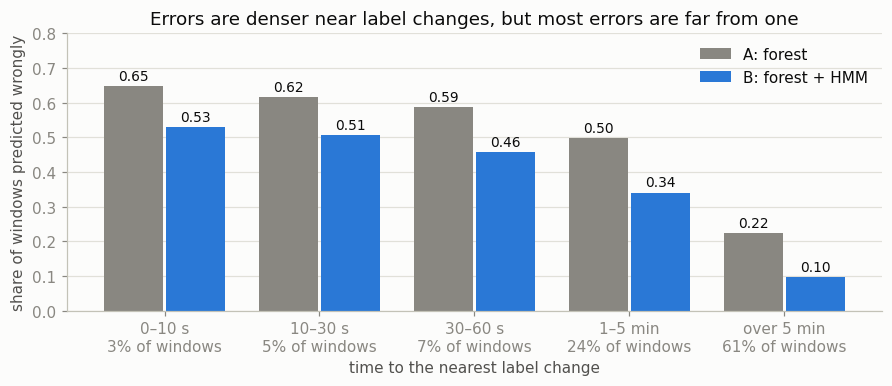

In [3]:
DISTANCE = har.windows_to_change(Y, SEQ)
BINS = {"0–10 s": (0, 0), "10–30 s": (1, 2), "30–60 s": (3, 5), "1–5 min": (6, 29), "over 5 min": (30, 10**9)}


def in_bin(rows, name):
    lo, hi = BINS[name]
    return (DISTANCE[rows] >= lo) & (DISTANCE[rows] <= hi)


MID = [in_bin(rows, "1–5 min") for rows in CV_ROWS]


def error_by_distance():
    """Error rate of A and B, share of windows and share of B's errors, by time to the nearest label change."""
    rows = np.concatenate(CV_ROWS)
    wrong = {m: np.concatenate(CV_PRED[m]) != Y[rows] for m in ("A", "B")}
    table = {}
    for name in BINS:
        here = in_bin(rows, name)
        table[name] = {"A error rate": wrong["A"][here].mean(), "B error rate": wrong["B"][here].mean(),
                       "share of windows": here.mean(), "share of B's errors": wrong["B"][here].sum() / wrong["B"].sum()}
    return pd.DataFrame(table).T


def mid_error(preds):
    """Error rate 1–5 min from a label change, mean over folds."""
    return np.mean([(pred[mid] != Y[rows][mid]).mean() for pred, rows, mid in zip(preds, CV_ROWS, MID)])


def plot_error_by_distance(table):
    fig, ax = plt.subplots(figsize=(8, 3.4), layout="constrained")
    x = np.arange(len(table))
    for offset, model, label, color in ((-0.2, "A", "A: forest", MUTED), (0.2, "B", "B: forest + HMM", BLUE)):
        bars = ax.bar(x + offset, table[f"{model} error rate"], width=0.38, color=color, label=label)
        ax.bar_label(bars, fmt="%.2f", padding=2, fontsize=9)
    ax.set_xticks(x, [f"{name}\n{share:.0%} of windows" for name, share in table["share of windows"].items()])
    ax.set(xlabel="time to the nearest label change", ylabel="share of windows predicted wrongly", ylim=(0, 0.8),
           title="Errors are denser near label changes, but most errors are far from one")
    ax.grid(axis="x", visible=False)
    ax.legend()
    fig.savefig(OUT / "error_by_distance.png", dpi=150)


ERRORS = error_by_distance()
plot_error_by_distance(ERRORS)
beyond_30s = [DISTANCE[rows] >= 3 for rows in CV_ROWS]
away = pd.DataFrame([metrics_from_cm(confusion_matrix(Y[rows][f], pred[f], labels=range(K)))
                     for rows, pred, f in zip(CV_ROWS, CV_PRED["B"], beyond_30s)])
print(pd.DataFrame({"all labelled windows": B_CV[list(SHOWN)].mean(),
                    "more than 30 s from a change": away[list(SHOWN)].mean()}).rename(index=SHOWN).round(3).to_string())
ERRORS.round(3)

Errors are denser near label changes: B is wrong on 53% of windows within 10 s of a change and on 10% of windows more than 5 min from one. But few windows are near a change. Those within 30 s are 8% of windows and 19% of B's errors, and scoring B without them raises κ from 0.708 to 0.737 and macro-F1 from 0.522 to 0.533. So uncertain label timing explains at most about 0.03 κ, and that is an upper bound: windows near a change also sit in short bouts, which are harder for other reasons.

Two thirds of B's errors are more than a minute from any change. The 1–5 min bin holds the largest share, 39% of the errors: bouts of a few minutes that B gets wrong as a whole.

### Activities almost never touch in the labels

In [4]:
def label_changes():
    """How labelled runs end, and what that does to B's transition matrix, on P001-P100."""
    adjacent = (SEQ[1:] == SEQ[:-1]) & IS_DEV[1:]
    both = adjacent & LABELLED[1:] & LABELLED[:-1]
    change = adjacent & (Y[1:] != Y[:-1])
    dev = np.flatnonzero(IS_DEV & LABELLED)
    counted, across = fit_hmm(Y[IS_DEV], SEQ[IS_DEV], K)["trans"], fit_hmm(Y[dev], PARTICIPANT[dev], K)["trans"]
    off = ~np.eye(K, dtype=bool)
    print(f"adjacent pairs of labelled windows: {both.sum():,}; of those, two different activities: {(both & change).sum()}")
    print(f"label changes: {change.sum():,}; into or out of 'unlabelled': {(change & ~both).sum():,}")
    print(f"B's transition matrix: {(counted[off] == 0).sum()} of {off.sum()} off-diagonal entries are zero; "
          f"chance of leaving an activity in one step {round(1 - np.diag(counted).max(), 4):g} to {round(1 - np.diag(counted).min(), 4):g}")
    print(f"counted across unlabelled gaps: {(across[off] == 0).sum()} zeros; "
          f"chance of leaving {1 - np.diag(across).max():.4f} to {1 - np.diag(across).min():.4f}")


label_changes()
CV_PRED["B, transitions across gaps"] = hmm_cv(FOREST_CV, divide=False, across_gaps=True)
pd.DataFrame({name: {**cv_scores(preds)[list(SHOWN)].mean().round(3).rename(SHOWN), **against(cv_scores(preds), B_CV)}
              for name, preds in CV_PRED.items() if name != "A"}).T

adjacent pairs of labelled windows: 609,580; of those, two different activities: 46
label changes: 16,948; into or out of 'unlabelled': 16,902
B's transition matrix: 72 of 90 off-diagonal entries are zero; chance of leaving an activity in one step 0 to 0.0006
counted across unlabelled gaps: 11 zeros; chance of leaving 0.0004 to 0.0416


,macro-F1,κ,macro-F1 against B,κ against B
B,0.522,0.708,+0.000 ± 0.000,+0.000 ± 0.000
"B, transitions across gaps",0.529,0.697,+0.008 ± 0.007,-0.012 ± 0.005


Annotators leave an unlabelled gap at almost every change of activity. Only 46 of the 609,580 adjacent pairs of labelled windows are two different activities; the other 16,902 label changes go into or out of "unlabelled". B counts transitions between adjacent labelled windows only, so 72 of the 90 off-diagonal entries of its transition matrix are zero and the chance of leaving an activity in one step is at most 0.0006: close to "never switch unless the forest insists".

Counting across the gaps instead, as the paper's code does, gives switching chances of 0.0004 to 0.04, and B then scores −0.012 κ and +0.008 macro-F1, close to the "paper's sequences" row of part 1's ablation. The near-zero matrix is fitted on training participants only, so it is not a leak, but it is an accident of how the labels were made, not a model of how people change activity.

The gaps also explain why label timing costs so little above: the annotators had already cut the uncertain moments out. That analysis partly measures the annotation protocol.

### Does it work for everyone?

κ per participant from the same cross-validation predictions, with age group and sex from `metadata.csv`, and the whole recordings of the two lowest participants and the median one.

κ per participant: median 0.70, range 0.24 to 0.92; lowest five: P076 0.24, P052 0.36, P059 0.41, P065 0.46, P016 0.46


mean    sem  size
age 18-29  0.713  0.023    26
    30-37  0.715  0.025    27
    38-52  0.700  0.028    23
    53+    0.673  0.025    24
sex F      0.705  0.015    64
    M      0.695  0.022    36

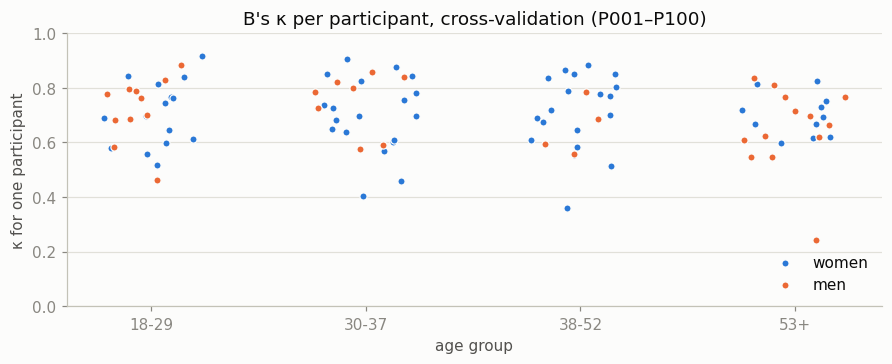

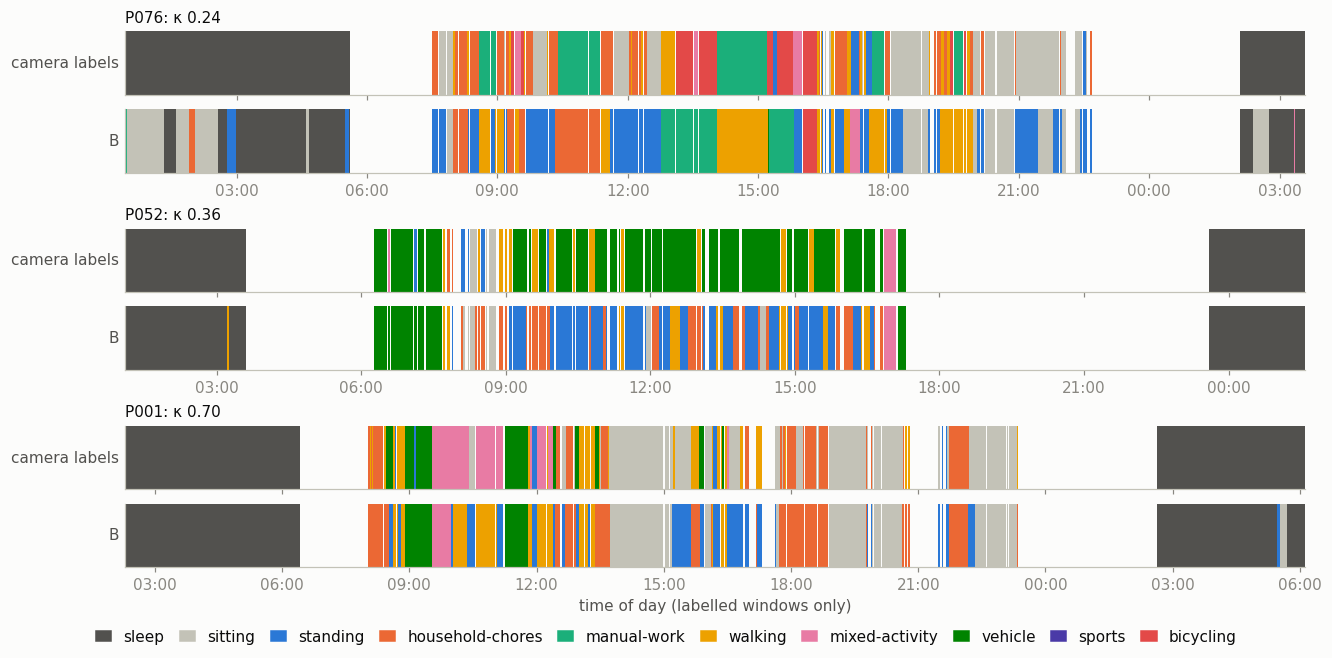

In [5]:
def participant_kappa(preds):
    rows = np.concatenate(CV_ROWS)
    table = pd.DataFrame({"participant": GROUPS[rows], "truth": Y[rows], "pred": np.concatenate(preds)})
    return table.groupby("participant").apply(
        lambda t: metrics_from_cm(confusion_matrix(t["truth"], t["pred"], labels=range(K)))["kappa"], include_groups=False)


def plot_participant_kappa(kappa, meta):
    ages = sorted(meta["age"].unique())
    jitter = np.random.default_rng(SEED)
    _, ax = plt.subplots(figsize=(8, 3.2), layout="constrained")
    for sex, label, color in (("F", "women", BLUE), ("M", "men", ORANGE)):
        who = meta.index[(meta["sex"] == sex) & meta.index.isin(kappa.index)]
        x = meta.loc[who, "age"].map(ages.index) + jitter.uniform(-0.25, 0.25, len(who))
        ax.scatter(x, kappa[who], s=22, color=color, edgecolor="#fcfcfb", linewidth=0.8, label=label)
    ax.set_xticks(range(len(ages)), ages)
    ax.set(xlabel="age group", ylabel="κ for one participant", ylim=(0, 1), title="B's κ per participant, cross-validation (P001–P100)")
    ax.grid(axis="x", visible=False)
    ax.legend(loc="lower right")


def plot_days(participants):
    """Camera labels and B's cross-validation predictions over the whole recording of each participant."""
    rows, pred = np.concatenate(CV_ROWS), np.concatenate(CV_PRED["B"])
    fig, axes = plt.subplots(2 * len(participants), 1, figsize=(12, 1.7 * len(participants) + 0.8), layout="constrained")
    for pid, pair in zip(participants, axes.reshape(-1, 2)):
        own = GROUPS[rows] == pid
        for ax, (name, codes) in zip(pair, {"camera labels": Y[rows], "B": pred}.items()):
            draw_band(ax, START[rows][own], codes[own], name)
            ax.set_xlim(START[rows][own].min(), START[rows][own].max())
            ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
        pair[0].set_title(f"{pid}: κ {KAPPA[pid]:.2f}", loc="left", fontsize=10)
        pair[0].set_xticklabels([])
    axes[-1].set_xlabel("time of day (labelled windows only)")
    har.class_legend(fig)
    fig.savefig(OUT / "worst_participants.png", dpi=150)


META = pd.read_csv(RAW / "metadata.csv", index_col="pid")
KAPPA = participant_kappa(CV_PRED["B"]).sort_values()
plot_participant_kappa(KAPPA, META)
plot_days([*KAPPA.index[:2], KAPPA.index[len(KAPPA) // 2]])
by = META.join(KAPPA.rename("kappa"), how="inner")
print(f"κ per participant: median {KAPPA.median():.2f}, range {KAPPA.min():.2f} to {KAPPA.max():.2f}; lowest five: "
      + ", ".join(f"{p} {k:.2f}" for p, k in KAPPA.head(5).items()))
pd.concat([by.groupby(col)["kappa"].agg(["mean", "sem", "size"]) for col in ("age", "sex")], keys=["age", "sex"]).round(3)

κ per participant has median 0.70 and runs from 0.24 to 0.92; five participants are at or below 0.46. Neither age nor sex explains it: the age groups differ by at most 0.04 with standard errors of about 0.025, and women and men by 0.01, though with 23–27 people per group only large differences would show. The timelines show what does: the two lowest participants had unusual days made of activities B confuses in general, and B gets whole spells wrong, not moments.

- **P076** did long spells of manual work and bicycling. B reads the manual work as household chores and walking, the bicycling as manual work, and part of the first two hours of sleep as sitting.
- **P052** spent about ten hours of the day in a vehicle. B follows the first hour, then reads the rest as standing, household chores and walking.
- **P001**, the median participant, has the usual errors: mixed activity read as walking, some sitting read as standing.

## 2. A pretrained encoder

**Model.** `harnet10` from `ssl-wearables`: an 18-layer 1D ResNet with about 11M parameters, pretrained without labels on 700,000 person-days of UK Biobank wrist data. It takes 10 s at 30 Hz, so each window is resized from 1,000 to 300 samples by linear interpolation, as its authors do, and stored once.

**Fine-tuning, fixed before any score was seen**, with the encoder's authors' settings where they give them: all layers, Adam with learning rate 1e-4, batches of 1,000 windows, no augmentation. A fifth of the training participants are held out for early stopping: training stops when their loss has not improved for 5 epochs, and the best epoch is kept.

**What the HMM needs.** B's HMM works because a balanced forest's output is roughly proportional to P(window | activity). A network trained with cross-entropy outputs P(activity | window), which already contains how common each activity is, so passing it to an HMM counts the class frequencies twice. Two remedies:

- **natural ÷ prior**: train on the data as it is, then divide the softmax by the training class frequencies;
- **balanced**: draw every batch with all activities equally frequent, and use the softmax as it is.

Each is combined with B's transitions and with transitions counted across gaps. The combination with the highest cross-validation macro-F1 goes to the held-out participants, once.

In [6]:
if not STORE.exists():
    deep.build_store(sorted(RAW.glob("P[0-9][0-9][0-9].csv.gz")), len(windows), STORE, STORE_START)
X30 = np.load(STORE, mmap_mode="r")  # (windows, 3, 300) float16 in the row order of `windows`, read from disk as needed
assert (np.load(STORE_START) == START).all(), "the 30 Hz store does not line up with the feature cache"


def early_stopping_split(train):
    """A fifth of the training participants, held out for early stopping; the same for every kind of fit and seed."""
    return har.early_stopping_split(Y, GROUPS, train, SEED)


def fine_tuned(variant, split, train, test, seed=SEED):
    """Softmax for every window of `test` of the encoder fine-tuned on the labelled windows of `train`."""
    def fit():
        fit_rows, val_rows = (rows[LABELLED[rows]] for rows in early_stopping_split(train))
        model = deep.fine_tune(X30, Y, fit_rows, val_rows, variant == "balanced", seed, **FINE_TUNING)
        return deep.encoder_proba(model, X30, test)
    return cached(fit, model="fine-tuned", variant=variant, split=split, seed=seed, settings=FINE_TUNING)


DEEP_CV = {variant: [fine_tuned(variant, f"fold{i}", train, valid) for i, (train, valid) in enumerate(FOLDS)]
           for variant in ("natural", "balanced")}

In [7]:
# name -> (variant, options for hmm_cv)
CANDIDATES = {"natural ÷ prior, B's transitions": ("natural", {}),
              "natural ÷ prior, transitions across gaps": ("natural", {"across_gaps": True}),
              "balanced, B's transitions": ("balanced", {"divide": False}),
              "balanced, transitions across gaps": ("balanced", {"divide": False, "across_gaps": True})}
DOUBLE_COUNTED = {"natural, softmax as it is, B's transitions": ("natural", {"divide": False})}


DEEP_PRED = {f"{variant} network alone": top_class_cv(probas) for variant, probas in DEEP_CV.items()}
DEEP_PRED |= {name: hmm_cv(DEEP_CV[variant], **options) for name, (variant, options) in (CANDIDATES | DOUBLE_COUNTED).items()}
DEEP_SCORES = {name: cv_scores(preds) for name, preds in DEEP_PRED.items()}
CHOSEN = max(CANDIDATES, key=lambda name: DEEP_SCORES[name]["macro_f1"].mean())
VARIANT, OPTIONS = CANDIDATES[CHOSEN]
print("chosen on cross-validation macro-F1:", CHOSEN)
assert not OPTIONS, "the held-out fit, the sweeps and the curves below assume natural ÷ prior with B's transitions"
pd.DataFrame({name: {**s[list(SHOWN)].mean().round(3).rename(SHOWN), **against(s, B_CV)} for name, s in DEEP_SCORES.items()}).T

chosen on cross-validation macro-F1: natural ÷ prior, B's transitions


,macro-F1,κ,macro-F1 against B,κ against B
natural network alone,0.49,0.658,-0.032 ± 0.013,-0.051 ± 0.012
balanced network alone,0.456,0.577,-0.065 ± 0.013,-0.131 ± 0.010
"natural ÷ prior, B's transitions",0.587,0.743,+0.065 ± 0.018,+0.035 ± 0.005
"natural ÷ prior, transitions across gaps",0.575,0.72,+0.053 ± 0.019,+0.011 ± 0.005
"balanced, B's transitions",0.586,0.759,+0.065 ± 0.017,+0.050 ± 0.009
"balanced, transitions across gaps",0.574,0.733,+0.052 ± 0.017,+0.025 ± 0.009
"natural, softmax as it is, B's transitions",0.513,0.749,-0.009 ± 0.017,+0.041 ± 0.017


- **Alone, the network is below B** (macro-F1 0.490 against 0.522), and balanced batches make it worse (0.456): it then over-predicts rare activities.
- **With an HMM it is above B** by 0.05–0.065 macro-F1 in all four combinations; the HMM adds about 0.10 macro-F1, as it does for the forest.
- **The two remedies tie on macro-F1** (0.587 and 0.586 with B's transitions), and balanced batches give the higher κ (0.759 against 0.743). The rule fixed in advance picks "natural ÷ prior, B's transitions" on a margin of 0.001, which means nothing.
- **The double counting is real.** The natural softmax passed to the HMM as it is loses 0.074 macro-F1. Its κ is not hurt (0.749), because κ rewards the common activities that double counting favours.
- **B's near-"never switch" matrix suits the network too:** counting across gaps costs 0.012 macro-F1 and 0.023–0.026 κ.

### What sets how often the HMM switches?

Viterbi replaces each of the 72 zeros in B's transition matrix with a floor, `TINY` = 1e-16, a cost of 37 nats. So the cost of most switches comes from a constant chosen to keep log(0) finite, not from data. Two checks, on the cross-validation folds, for B and the chosen fine-tuned model:

1. **Other floors** under the same counted matrix.
2. **An explicit switching rate p.** Stay with probability 1 − p; otherwise move to another activity in the proportions counted across gaps. This matrix has no zeros, so the floor plays no part.

                                macro-F1      κ  error rate 1–5 min from a change
explicit switching rate p                                                        
B                       0.1        0.517  0.678                             0.363
                        0.01       0.528  0.690                             0.351
                        0.001      0.531  0.696                             0.345
                        0.0001     0.530  0.697                             0.344
                        1e-05      0.528  0.698                             0.345
                        1e-06      0.528  0.698                             0.346
                        1e-08      0.524  0.697                             0.352
                        1e-10      0.520  0.697                             0.355
                        1e-13      0.511  0.692                             0.366
                        1e-16      0.503  0.686                             0.377
Deep + HMM      

macro-F1      κ  error rate 1–5 min from a change
counted matrix floor                                                    
B              0.0001     0.525  0.692                             0.349
               1e-08      0.529  0.702                             0.343
               1e-12      0.526  0.707                             0.341
               1e-16      0.522  0.708                             0.341
               1e-24      0.517  0.712                             0.339
Deep + HMM     0.0001     0.573  0.720                             0.303
               1e-08      0.578  0.731                             0.298
               1e-12      0.582  0.737                             0.293
               1e-16      0.587  0.743                             0.291
               1e-24      0.585  0.749                             0.287

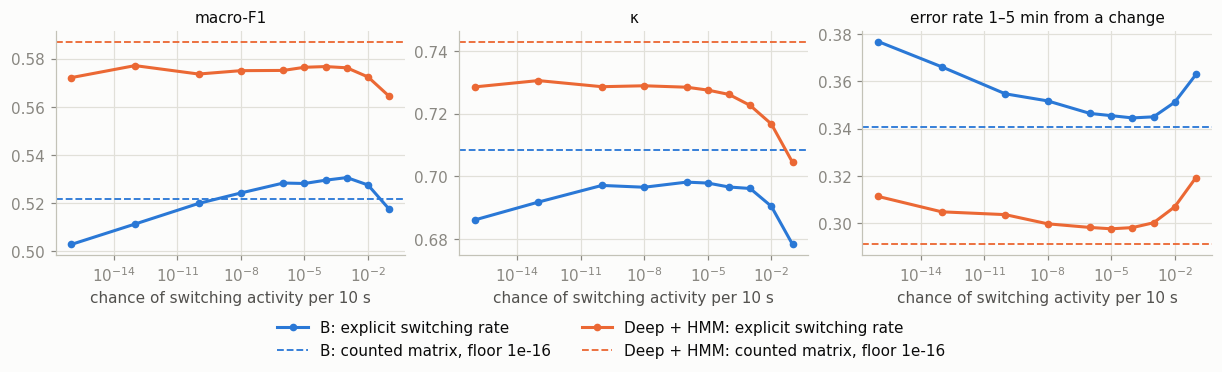

In [8]:
FLOORS = [1e-4, 1e-8, 1e-12, 1e-16, 1e-24]
RATES = [10.0**e for e in (-1, -2, -3, -4, -5, -6, -8, -10, -13, -16)]
LIKELIHOODS = {"B": FOREST_CV, "Deep + HMM": [proba / class_prior(train) for proba, (train, _) in zip(DEEP_CV[VARIANT], FOLDS)]}
COUNTED = [fit_hmm(Y[train], SEQ[train], K) for train, _ in FOLDS]


def switching_hmm(train, rate):
    """Stay with probability 1 - rate; otherwise move to another activity in the proportions counted across
    unlabelled gaps, plus one per pair so that none is zero."""
    labelled = train[LABELLED[train]]
    y, same = Y[labelled], PARTICIPANT[labelled][1:] == PARTICIPANT[labelled][:-1]
    moves = np.ones((K, K))
    np.add.at(moves, (y[:-1][same], y[1:][same]), 1)
    np.fill_diagonal(moves, 0)
    return {"prior": class_prior(train), "trans": (1 - rate) * np.eye(K) + rate * moves / moves.sum(axis=1, keepdims=True)}


def sweep_scores(liks, hmms, floor=TINY):
    preds = [decode(lik, hmm, valid, floor) for lik, hmm, (_, valid) in zip(liks, hmms, FOLDS)]
    return {**cv_scores(preds)[list(SHOWN)].mean().rename(SHOWN), "error rate 1–5 min from a change": mid_error(preds)}


def plot_rate_sweep():
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.3), layout="constrained")
    for ax, column in zip(axes, RATE_SWEEP.columns):
        for model, color in (("B", BLUE), ("Deep + HMM", ORANGE)):
            ax.plot(RATES, RATE_SWEEP.loc[model, column], color=color, marker="o", markersize=4, linewidth=2,
                    label=f"{model}: explicit switching rate")
            ax.axhline(FLOOR_SWEEP.loc[(model, TINY), column], color=color, linestyle="--", linewidth=1.2,
                       label=f"{model}: counted matrix, floor {TINY:g}")
        ax.set(xscale="log", xlabel="chance of switching activity per 10 s")
        ax.set_title(column, fontsize=10)
    fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncols=2)
    fig.savefig(OUT / "switching_rate.png", dpi=150)


FLOOR_SWEEP = pd.DataFrame({(model, floor): sweep_scores(liks, COUNTED, floor)
                            for model, liks in LIKELIHOODS.items() for floor in FLOORS}).T
RATE_SWEEP = pd.DataFrame({(model, rate): sweep_scores(liks, [switching_hmm(train, rate) for train, _ in FOLDS])
                           for model, liks in LIKELIHOODS.items() for rate in RATES}).T
plot_rate_sweep()
print(RATE_SWEEP.rename(index="{:g}".format, level=1).rename_axis(["explicit switching rate", "p"]).round(3).to_string())
FLOOR_SWEEP.rename(index="{:g}".format, level=1).rename_axis(["counted matrix", "floor"]).round(3)

- **The floor is a hidden setting.** From 1e-4 to 1e-24, κ moves from 0.692 to 0.712 for B and from 0.720 to 0.749 for the fine-tuned model, comparable to B's held-out gain of 0.03 over the paper's pipeline. It was never tuned, and smaller floors score slightly higher κ.
- **An explicit rate does not beat it.** Scores are flat from p = 1e-3 to 1e-8. Even the best p on these folds, a choice that flatters it, is 0.010 κ below the counted matrix for B and 0.012 below for the fine-tuned model, so nothing was changed.
- **The smoother is not what hides short bouts.** If switching cost too much, a higher rate would lower the error rate 1–5 min from a label change. It does not: its lowest value over all rates is 0.344 for B, against 0.341 with the counted matrix. Those errors come from the classifier.

The HMM holds the current activity until the evidence against it is strong and lasts; how strong hardly matters over five orders of magnitude.

### Spread over fine-tuning seeds

The chosen combination is fitted twice more on the five folds, with other seeds for the classifier head and the batch order. No held-out look.

In [9]:
DEEP_SEEDS = {seed: [fine_tuned(VARIANT, f"fold{i}", train, valid, seed) for i, (train, valid) in enumerate(FOLDS)] for seed in SEEDS}
DEEP_SEED_PRED = {seed: hmm_cv(probas, **OPTIONS) for seed, probas in DEEP_SEEDS.items()}
SEED_SCORES = {seed: cv_scores(preds) for seed, preds in DEEP_SEED_PRED.items()}
SEED_MEANS = pd.DataFrame({seed: scores[list(SHOWN)].mean() for seed, scores in SEED_SCORES.items()}).T.rename(columns=SHOWN)
print("standard deviation over seeds:", SEED_MEANS.std().round(4).to_dict())
pd.DataFrame({f"seed {seed}": {**scores[list(SHOWN)].mean().round(3).rename(SHOWN), **against(scores, B_CV)}
              for seed, scores in SEED_SCORES.items()}).T

standard deviation over seeds: {'macro-F1': 0.0079, 'κ': 0.0102}


,macro-F1,κ,macro-F1 against B,κ against B
seed 42,0.587,0.743,+0.065 ± 0.018,+0.035 ± 0.005
seed 43,0.572,0.75,+0.050 ± 0.014,+0.042 ± 0.005
seed 44,0.575,0.73,+0.054 ± 0.022,+0.022 ± 0.007


Over three seeds the cross-validation means vary by 0.008 macro-F1 and 0.010 κ (standard deviation), and the gain over B is positive for every seed: +0.050 to +0.065 macro-F1 and +0.022 to +0.042 κ. The held-out fit uses seed 42, in the middle of that range for κ and at the top for macro-F1.

### Held-out participants

The chosen combination is fitted on P001–P100 and scored on P101–P151, once. B is refitted too, and reproduces part 1's held-out scores. Intervals are 95% percentile bootstraps over participants (2,000 draws), and differences between models are paired: the same draws of participants for both.

In [10]:
DEV, TEST = np.flatnonzero(IS_DEV), np.flatnonzero(~IS_DEV)
SCORED = TEST[LABELLED[TEST]]
DEEP_TEST = fine_tuned(VARIANT, "holdout", DEV, TEST)
HOLDOUT_PRED = {"B": hmm_predict(forest_proba(DEV, TEST), DEV, TEST),
                "Deep": top_class(DEEP_TEST, TEST),
                "Deep + HMM": hmm_predict(DEEP_TEST / class_prior(DEV), DEV, TEST)}


def holdout_cms(pred):
    """Confusion matrix per held-out participant."""
    return har.participant_cms(Y[SCORED], pred, GROUPS[SCORED], K)


def score_holdout(pred):
    cms = holdout_cms(pred)
    point, draws = metrics_from_cm(cms.sum(axis=0)), har.bootstrap_metrics(cms, N_BOOT, SEED)
    return {**{m: interval(point[m], draws[m]) for m in SHOWN}, "per_class_f1": point["per_class_f1"]}


def paired_gain(pred, baseline):
    return har.paired_gain(holdout_cms(pred), holdout_cms(baseline), SHOWN, N_BOOT, SEED)


def holdout_table(models, gains):
    cell = lambda s, sign="": f"{s['value']:{sign}.3f} [{s['ci'][0]:{sign}.3f}, {s['ci'][1]:{sign}.3f}]"
    rows = {model: {label: cell(SCORES[model][m]) for m, label in SHOWN.items()} for model in models}
    rows |= {name: {label: cell(gain[m], "+") for m, label in SHOWN.items()} for name, gain in gains.items()}
    return pd.DataFrame(rows).T


SCORES = {model: score_holdout(pred) for model, pred in HOLDOUT_PRED.items()}
assert np.allclose([SCORES["B"][m]["value"] for m in SHOWN], [PART1["tasks"]["10-class"]["B"]["holdout"][m]["value"] for m in SHOWN])
GAINS = {"Deep + HMM minus B": paired_gain(HOLDOUT_PRED["Deep + HMM"], HOLDOUT_PRED["B"])}
holdout_table(SCORES, GAINS)

,macro-F1,κ
B,"0.566 [0.524, 0.595]","0.690 [0.653, 0.725]"
Deep,"0.513 [0.466, 0.546]","0.650 [0.620, 0.679]"
Deep + HMM,"0.619 [0.557, 0.659]","0.742 [0.702, 0.778]"
Deep + HMM minus B,"+0.053 [+0.013, +0.085]","+0.052 [+0.029, +0.074]"


,B CV,Deep + HMM CV,B held out,Deep + HMM held out
sleep,0.970,0.963,0.980,0.971
sitting,0.861,0.879,0.873,0.897
standing,0.277,0.365,0.300,0.379
household-chores,0.596,0.630,0.531,0.609
manual-work,0.146,0.199,0.072,0.084
walking,0.422,0.521,0.426,0.492
mixed-activity,0.184,0.213,0.136,0.374
vehicle,0.792,0.880,0.733,0.950
sports,0.251,0.452,0.802,0.663
bicycling,0.820,0.913,0.810,0.776


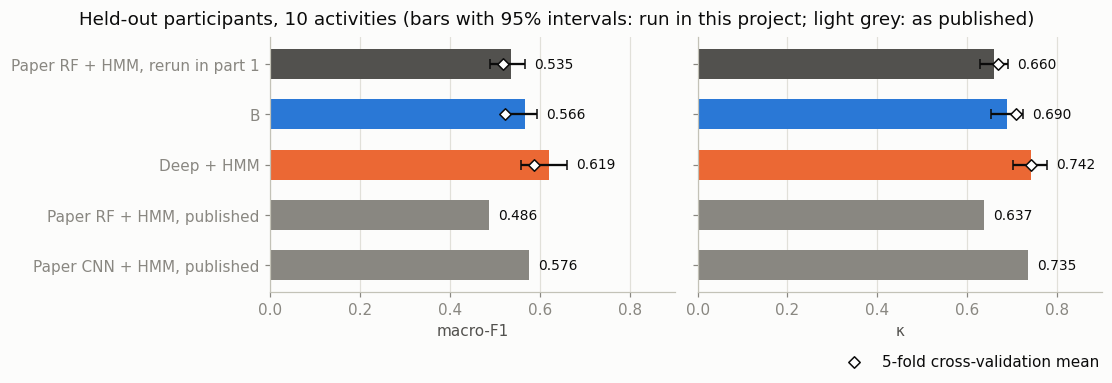

In [11]:
RERUN = PART1["paper_copy_10-class"]
# name -> (held-out scores, cross-validation means, colour), for the figure
SHOWN_MODELS = {"Paper RF + HMM, rerun in part 1": (RERUN["holdout"], {m: RERUN["cv"][m]["mean"] for m in SHOWN}, "#52514e"),
                "B": (SCORES["B"], B_CV[list(SHOWN)].mean(), BLUE),
                "Deep + HMM": (SCORES["Deep + HMM"], DEEP_SCORES[CHOSEN][list(SHOWN)].mean(), ORANGE)}


def plot_holdout():
    title = "Held-out participants, 10 activities (bars with 95% intervals: run in this project; light grey: as published)"
    har.plot_holdout(SHOWN_MODELS, PUBLISHED, title).savefig(OUT / "results_new_model.png", dpi=150)


plot_holdout()
pd.DataFrame({"B CV": pooled_f1(CV_PRED["B"]), "Deep + HMM CV": pooled_f1(DEEP_PRED[CHOSEN]),
              "B held out": SCORES["B"]["per_class_f1"], "Deep + HMM held out": SCORES["Deep + HMM"]["per_class_f1"]},
             index=CODES).loc[CLASSES].round(3)

The fine-tuned encoder + HMM beats B on the held-out participants, paired: +0.053 macro-F1 (0.013 to 0.085) and +0.052 κ (0.029 to 0.074). It matches the paper's deep model without clearly beating it: the published 0.576 and 0.735 are inside both intervals. In cross-validation every activity but sleep improves, most of all sports, walking and bicycling.

## 3. A model that sees minutes

The sweep and the timelines point the same way: the smoother is not the bottleneck, and the worst days are whole spells misread by a classifier that sees 10 seconds at a time. So: **does context from minutes recover the bouts that a single-window model misreads?** This text, up to the held-out scores, was written before any score of the new model was seen.

**Model.** Every window goes once through the encoder as downloaded, never trained on CAPTURE-24 labels, which gives 1,024 numbers per window. A 2-layer bidirectional GRU (128 units per direction, dropout 0.5) reads them for consecutive windows and outputs an activity for each. It trains on chunks of 64 consecutive windows (about 10 min), a new chunk every 32 windows; unlabelled windows are part of the input and carry no loss. At prediction it reads each whole recording.

**Control.** The same network on single windows. It shares the frozen encoder, so the difference between the two is context.

**Settings.** Adam with learning rate 1e-3, 16,384 windows per batch, early stopping on the same held-out participants as the fine-tuning (5 epochs without improvement), natural class frequencies, three seeds per fold, the same five folds.

**Selection.** Two candidates: the context model's top class, and its softmax ÷ prior through the same HMM as Deep + HMM. The one with the higher cross-validation macro-F1 (mean over seeds) is scored on the held-out participants, once, with seed 42; if they are within 0.005, the higher κ decides. The held-out comparison is paired with Deep + HMM.

**Direct tests**, in cross-validation: the error rate 1–5 min from a label change, and κ for P052.

In [12]:
if not deep.EMBEDDINGS.exists():
    deep.build_embeddings(X30, deep.EMBEDDINGS)
EMBEDDED = np.load(deep.EMBEDDINGS, mmap_mode="r")  # (windows, 1024) float16, read from disk as needed
LENGTHS = {1: "single windows", CONTEXT_LENGTH: f"{CONTEXT_LENGTH} windows of context"}


def context_fit(inputs, length, split, train, test, seed=SEED):
    """Softmax for every window of `test` of the recurrent network trained on `train` with chunks of `length` windows."""
    def fit():
        Z = EMBEDDED if inputs == "encoder" else scaled_features(train)
        model = deep.fit_context(Z, Y, SEQ, *early_stopping_split(train), length, seed, **CONTEXT)
        return deep.context_proba(model, Z, SEQ, test, length)
    return cached(fit, model="context", inputs=inputs, length=length, split=split, seed=seed, settings=CONTEXT)


def context_cv(inputs, length, seed):
    return [context_fit(inputs, length, f"fold{i}", train, valid, seed) for i, (train, valid) in enumerate(FOLDS)]


CONTEXT_CV = {(length, seed): context_cv("encoder", length, seed) for length in LENGTHS for seed in SEEDS}

In [13]:
def summary(by_seed):
    """Per-fold scores averaged over seeds, and the cross-validation tests: mean and spread over seeds."""
    tests = pd.DataFrame([{**cv_scores(preds)[list(SHOWN)].mean().rename(SHOWN), "error rate 1–5 min from a change": mid_error(preds),
                           "κ for P052": participant_kappa(preds)["P052"]} for preds in by_seed])
    fold_mean = sum(cv_scores(preds)[list(SHOWN)] for preds in by_seed) / len(by_seed)
    spread = {f"{label}, spread over seeds": tests[label].std() for label in SHOWN.values()}
    return fold_mean, {**tests.mean(), **spread}


MODELS = {"Deep + HMM": list(DEEP_SEED_PRED.values())}
MODELS |= {f"frozen encoder, {label}{suffix}": [decide(CONTEXT_CV[length, seed]) for seed in SEEDS]
           for length, label in LENGTHS.items() for suffix, decide in (("", top_class_cv), (" + HMM", hmm_cv))}
SUMMARY = {name: summary(by_seed) for name, by_seed in MODELS.items()}
CONTEXT_SCORES = {name: fold_mean for name, (fold_mean, _) in SUMMARY.items()}
ALONE, WITH_HMM = (f"frozen encoder, {LENGTHS[CONTEXT_LENGTH]}{suffix}" for suffix in ("", " + HMM"))
# The rule, fixed before any score: the higher cross-validation macro-F1; within 0.005 of each other, the higher κ.
TIE = abs(CONTEXT_SCORES[ALONE]["macro_f1"].mean() - CONTEXT_SCORES[WITH_HMM]["macro_f1"].mean()) < 0.005
CONTEXT_CHOSEN = max((ALONE, WITH_HMM), key=lambda name: CONTEXT_SCORES[name]["kappa" if TIE else "macro_f1"].mean())
print("chosen for the held-out participants:", CONTEXT_CHOSEN, "(by κ: within 0.005 macro-F1)" if TIE else "")
CONTEXT_TABLE = pd.DataFrame({"B": {"error rate 1–5 min from a change": mid_error(CV_PRED["B"]), "κ for P052": KAPPA["P052"],
                                    **B_CV[list(SHOWN)].mean().rename(SHOWN)}}
                             | {name: row for name, (_, row) in SUMMARY.items()}).T
CHANGE = {name: against(scores, CONTEXT_SCORES["Deep + HMM"], "Deep + HMM")
          for name, scores in CONTEXT_SCORES.items() if name != "Deep + HMM"}
CONTEXT_TABLE = CONTEXT_TABLE.join(pd.DataFrame(CHANGE).T)
CONTEXT_TABLE.map(lambda v: round(v, 3) if isinstance(v, float) else v).fillna("")

chosen for the held-out participants: frozen encoder, 64 windows of context (by κ: within 0.005 macro-F1)


,error rate 1–5 min from a change,κ for P052,macro-F1,κ,"macro-F1, spread over seeds","κ, spread over seeds",macro-F1 against Deep + HMM,κ against Deep + HMM
B,0.341,0.360,0.522,0.708,,,,
Deep + HMM,0.286,0.365,0.578,0.741,0.008,0.01,,
"frozen encoder, single windows",0.330,0.320,0.488,0.668,0.002,0.0,-0.090 ± 0.012,-0.073 ± 0.015
"frozen encoder, single windows + HMM",0.250,0.367,0.603,0.776,0.003,0.002,+0.025 ± 0.016,+0.035 ± 0.014
"frozen encoder, 64 windows of context",0.209,0.388,0.580,0.814,0.011,0.001,+0.002 ± 0.016,+0.072 ± 0.014
"frozen encoder, 64 windows of context + HMM",0.284,0.356,0.584,0.766,0.007,0.011,+0.006 ± 0.009,+0.025 ± 0.012


All rows but B are means over the same three seeds.

- **Context does what it was built for.** The error rate 1–5 min from a label change is 0.21, against 0.29 for the fine-tuned encoder + HMM, 0.25 for the single-window control + HMM and 0.34 for B. κ is 0.814, +0.072 (standard error 0.014) against the fine-tuned model on the same folds. Macro-F1 does not move (0.580 against 0.578).
- **P052 does not move.** κ is 0.39, against 0.37 for the fine-tuned model and 0.36 for B; for one person that is noise. Why ten hours in a vehicle are misread stays open.
- **The HMM no longer helps.** On top of the context model it lowers κ from 0.814 to 0.766 and leaves macro-F1 where it was. This fits the switching-rate section: the near-"never switch" matrix appears to act as a flicker filter, and once the network removes the flicker itself the matrix only holds too long. The two candidates are within 0.005 macro-F1, so the higher κ decides: the context model alone goes to the held-out participants.
- **The control is a result in itself.** The frozen encoder with a single-window network and the HMM scores macro-F1 0.603 and κ 0.776, +0.025 and +0.035 against the fine-tuned encoder. So this fine-tuning recipe (learning rate 1e-4, best epoch the first or second) did not beat a small network on the frozen encoder. A gentler schedule was not tried, and the encoder's authors report fine-tuning slightly ahead of a frozen encoder, so this says something about the recipe, not about fine-tuning. The control was not a candidate and is not scored on the held-out participants.
- **Seeds matter little:** the spread over three seeds is at most 0.011.

The rows differ in decision rule as well as in model: the context model alone keeps the class frequencies in its softmax, while the rows with an HMM have them divided out. The section after the held-out scores separates the two.

,macro-F1,κ
B,"0.566 [0.524, 0.595]","0.690 [0.653, 0.725]"
Deep + HMM,"0.619 [0.557, 0.659]","0.742 [0.702, 0.778]"
Context,"0.642 [0.577, 0.677]","0.790 [0.758, 0.819]"
Context minus Deep + HMM,"+0.022 [-0.025, +0.057]","+0.048 [+0.026, +0.071]"
Context minus B,"+0.076 [+0.021, +0.111]","+0.100 [+0.076, +0.124]"


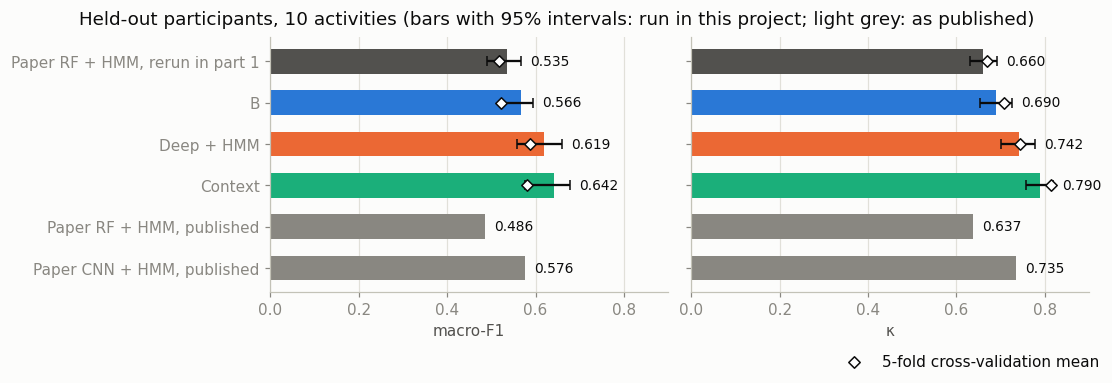

In [14]:
CONTEXT_MODEL = "Context + HMM" if CONTEXT_CHOSEN == WITH_HMM else "Context"
CONTEXT_TEST = context_fit("encoder", CONTEXT_LENGTH, "holdout", DEV, TEST)
HOLDOUT_PRED[CONTEXT_MODEL] = (hmm_predict(CONTEXT_TEST / class_prior(DEV), DEV, TEST) if CONTEXT_CHOSEN == WITH_HMM
                         else top_class(CONTEXT_TEST, TEST))
SCORES[CONTEXT_MODEL] = score_holdout(HOLDOUT_PRED[CONTEXT_MODEL])
GAINS |= {f"{CONTEXT_MODEL} minus {base}": paired_gain(HOLDOUT_PRED[CONTEXT_MODEL], HOLDOUT_PRED[base]) for base in ("Deep + HMM", "B")}
SHOWN_MODELS[CONTEXT_MODEL] = (SCORES[CONTEXT_MODEL], CONTEXT_SCORES[CONTEXT_CHOSEN][list(SHOWN)].mean(), GREEN)
plot_holdout()
holdout_table(["B", "Deep + HMM", CONTEXT_MODEL], {name: gain for name, gain in GAINS.items() if name.startswith(CONTEXT_MODEL)})

In [15]:
pd.DataFrame({"Deep + HMM CV": pooled_f1(DEEP_PRED[CHOSEN]),
              f"{CONTEXT_MODEL} CV (seed 42)": pooled_f1(MODELS[CONTEXT_CHOSEN][0]),
              "Deep + HMM held out": SCORES["Deep + HMM"]["per_class_f1"],
              f"{CONTEXT_MODEL} held out": SCORES[CONTEXT_MODEL]["per_class_f1"]},
             index=CODES).loc[CLASSES].round(3)

,Deep + HMM CV,Context CV (seed 42),Deep + HMM held out,Context held out
sleep,0.963,0.992,0.971,0.993
sitting,0.879,0.937,0.897,0.928
standing,0.365,0.312,0.379,0.348
household-chores,0.630,0.701,0.609,0.631
manual-work,0.199,0.012,0.084,0.212
walking,0.521,0.548,0.492,0.546
mixed-activity,0.213,0.288,0.374,0.340
vehicle,0.880,0.883,0.950,0.966
sports,0.452,0.299,0.663,0.604
bicycling,0.913,0.872,0.776,0.851


On the held-out participants the context model scores macro-F1 0.642 (95% interval 0.577 to 0.677) and κ 0.790 (0.758 to 0.819).

- **Against the fine-tuned encoder + HMM, paired:** +0.048 κ (0.026 to 0.071) and +0.022 macro-F1 (−0.025 to 0.057), which is not reliable. As in cross-validation: more agreement, the same macro-F1.
- **Against B, paired:** +0.100 κ (0.076 to 0.124) and +0.076 macro-F1 (0.021 to 0.111).
- **These pairs compare different decision rules.** The context model keeps the class frequencies; B and the fine-tuned model have them removed. With each model at its best rule the cross-validation gaps in κ are about 40% smaller (next section).
- **Against the paper's CNN + HMM**, not paired: its published κ, 0.735, is below this interval, and its macro-F1, 0.576, at the interval's lower edge. Read it as "above on κ, not shown on macro-F1".
- **By activity it trades rare activities for common ones.** In cross-validation (seed 42) it gains on sleep, sitting, household chores and mixed activity and loses on manual work, sports and standing; over three seeds manual work goes from F1 0.13 to 0.06. That is why κ rises and macro-F1 does not. On the held-out participants manual work and bicycling go the other way, which shows how unstable rare activities are with 51 participants.

Cross-validation macro-F1, 0.580, is the safer figure to quote than 0.642.

### The decision rule, and what the encoder is worth

The comparisons above mix the model with the rule that turns its output into a class. Keeping the class frequencies favours common activities and κ; removing them favours rare activities and macro-F1. So every model is scored here with its output ÷ prior^α, from α = 0 (frequencies kept) to α = 1 (removed), on the cross-validation folds, averaged over three seeds (B has one fit).

To separate the encoder from the sequence model, the same two networks, single-window with the HMM and 64-window context, are also trained on B's 39 hand-made features, standardised with each fold's training participants. They were added after the held-out scores above, so they are scored in cross-validation only.

                                          best κ  macro-F1 there  best macro-F1  κ there
B                                          0.749           0.485          0.522    0.708
Deep + HMM                                 0.772           0.566          0.582    0.768
Single windows + HMM                       0.793           0.588          0.603    0.776
Context                                    0.814           0.580          0.593    0.790
Context + HMM                              0.806           0.568          0.584    0.766
Hand-made features, single windows + HMM   0.724           0.483          0.500    0.670
Hand-made features, context                0.780           0.536          0.547    0.764


macro-F1      κ  \
model                                    α                       
B                                        0.00     0.391  0.683   
                                         0.25     0.424  0.710   
                                         0.50     0.445  0.732   
                                         0.75     0.485  0.749   
                                         1.00     0.522  0.708   
Deep + HMM                               0.00     0.512  0.749   
                                         0.25     0.535  0.764   
                                         0.50     0.566  0.772   
                                         0.75     0.582  0.768   
                                         1.00     0.578  0.741   
Single windows + HMM                     0.00     0.508  0.761   
                                         0.25     0.530  0.778   
                                         0.50     0.562  0.789   
                                         0.75     0.588  0.793   
                                         1.00     0.603  0.776   
Context                                  0.00     0.580  0.814   
                                         0.25     0.589  0.811   
                                         0.50     0.593  0.804   
                                         0.75     0.593  0.790   
                                         1.00     0.589  0.770   
Context + HMM                            0.00     0.568  0.806   
                                         0.25     0.575  0.804   
                                         0.50     0.582  0.799   
                                         0.75     0.584  0.785   
                                         1.00     0.584  0.766   
Hand-made features, single windows + HMM 0.00     0.390  0.678   
                                         0.25     0.415  0.702   
                                         0.50     0.441  0.719   
                                         0.75     0.483  0.724   
                                         1.00     0.500  0.670   
Hand-made features, context              0.00     0.536  0.780   
                                         0.25     0.547  0.775   
                                         0.50     0.547  0.764   
                                         0.75     0.544  0.745   
                                         1.00     0.535  0.718   

                                               F1 for manual work  
model                                    α                         
B                                        0.00               0.000  
                                         0.25               0.000  
                                         0.50               0.000  
                                         0.75               0.000  
                                         1.00               0.146  
Deep + HMM                               0.00               0.011  
                                         0.25               0.018  
                                         0.50               0.071  
                                         0.75               0.102  
                                         1.00               0.129  
Single windows + HMM                     0.00               0.000  
                                         0.25               0.004  
                                         0.50               0.041  
                                         0.75               0.040  
                                         1.00               0.241  
Context                                  0.00               0.060  
                                         0.25               0.077  
                                         0.50               0.088  
                                         0.75               0.114  
                                         1.00               0.139  
Context + HMM                            0.00               0.066  
                                        

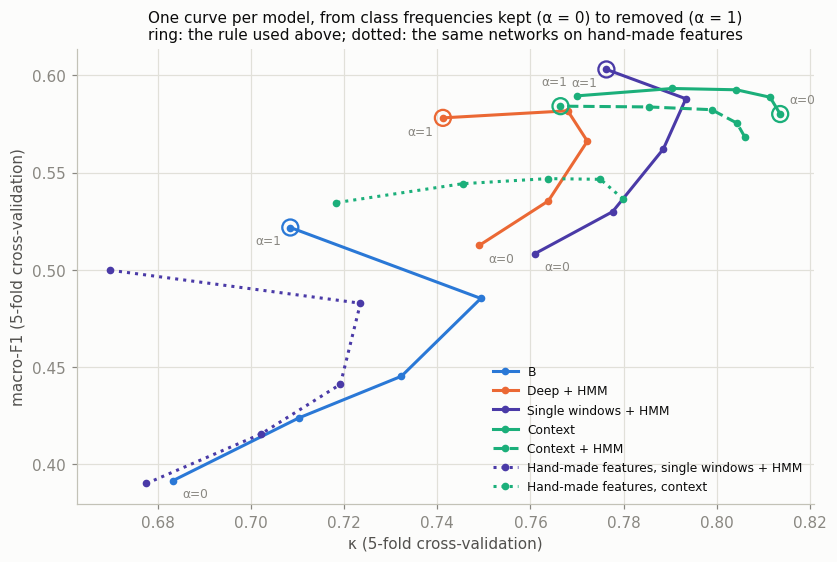

In [16]:
def scaled_features(train):
    mean, sd = X[train].mean(axis=0), X[train].std(axis=0)
    return ((X - mean) / sd).astype(np.float32)


FEATURE_CV = {(length, seed): context_cv("features", length, seed) for length in LENGTHS for seed in SEEDS}
ALPHAS = [0, 0.25, 0.5, 0.75, 1]
MANUAL = CODES.index("manual-work")
# name -> (one list of fold outputs per seed, HMM, forest, colour, line style, alpha used in the tables above)
CURVES = {"B": ([FOREST_CV], True, True, BLUE, "-", 1),
          "Deep + HMM": (list(DEEP_SEEDS.values()), True, False, ORANGE, "-", 1),
          "Single windows + HMM": ([CONTEXT_CV[1, seed] for seed in SEEDS], True, False, PURPLE, "-", 1),
          "Context": ([CONTEXT_CV[CONTEXT_LENGTH, seed] for seed in SEEDS], False, False, GREEN, "-", 0),
          "Context + HMM": ([CONTEXT_CV[CONTEXT_LENGTH, seed] for seed in SEEDS], True, False, GREEN, "--", 1),
          "Hand-made features, single windows + HMM": ([FEATURE_CV[1, seed] for seed in SEEDS], True, False, PURPLE, ":", None),
          "Hand-made features, context": ([FEATURE_CV[CONTEXT_LENGTH, seed] for seed in SEEDS], False, False, GREEN, ":", None)}


def prior_curve(by_seed, hmm, forest):
    """Cross-validation scores, mean over seeds, with the class frequencies removed to the power alpha: output ÷ prior^alpha.
    A balanced forest's output has them removed already, so there they are put back: output × prior^(1 - alpha)."""
    curve = {}
    for alpha in ALPHAS:
        per_seed = []
        for probas in by_seed:
            liks = [proba * class_prior(train) ** (1 - alpha if forest else -alpha) for proba, (train, _) in zip(probas, FOLDS)]
            preds = hmm_cv(liks, divide=False) if hmm else top_class_cv(liks)
            per_seed.append({**cv_scores(preds)[list(SHOWN)].mean().rename(SHOWN), "F1 for manual work": pooled_f1(preds)[MANUAL]})
        curve[alpha] = pd.DataFrame(per_seed).mean()
    return pd.DataFrame(curve).T


def plot_rule_curves():
    fig, ax = plt.subplots(figsize=(7.5, 5), layout="constrained")
    for name, (*_, color, style, used) in CURVES.items():
        curve = RULE[name]
        ax.plot(curve["κ"], curve["macro-F1"], color=color, linestyle=style, linewidth=2, marker="o", markersize=4, label=name)
        if used is not None:
            ax.scatter(*curve.loc[used, ["κ", "macro-F1"]], s=110, facecolor="none", edgecolor=color, linewidth=1.5, zorder=3)
        if style == "-":
            for alpha, dx in ((0, 6), (1, -6)):
                ax.annotate(f"α={alpha}", curve.loc[alpha, ["κ", "macro-F1"]], xytext=(dx, 7 if name == "Context" else -11),
                            textcoords="offset points", ha="left" if dx > 0 else "right", fontsize=8, color=MUTED)
    ax.set(xlabel="κ (5-fold cross-validation)", ylabel="macro-F1 (5-fold cross-validation)")
    ax.set_title("One curve per model, from class frequencies kept (α = 0) to removed (α = 1)\n"
                 "ring: the rule used above; dotted: the same networks on hand-made features", fontsize=10)
    ax.legend(loc="lower right", fontsize=8)
    fig.savefig(OUT / "decision_rule.png", dpi=150)


RULE = {name: prior_curve(by_seed, hmm, forest) for name, (by_seed, hmm, forest, *_) in CURVES.items()}
plot_rule_curves()
BEST = pd.DataFrame({name: {"best κ": curve["κ"].max(), "macro-F1 there": curve.loc[curve["κ"].idxmax(), "macro-F1"],
                            "best macro-F1": curve["macro-F1"].max(), "κ there": curve.loc[curve["macro-F1"].idxmax(), "κ"]}
                     for name, curve in RULE.items()}).T
print(BEST.round(3).to_string())
pd.concat(RULE).rename_axis(["model", "α"]).round(3)

**Reading the curves.** At each model's best rule for κ: Context 0.814, Context + HMM 0.806, single windows + HMM 0.793, hand-made features with context 0.780, Deep + HMM 0.772, B 0.749, hand-made features with single windows + HMM 0.724.

- **The encoder and context overlap.** On B's hand-made features the two networks score 0.724 and 0.780; on the encoder's output, 0.793 and 0.814. The encoder adds 0.070 without context and 0.034 with it; context adds 0.056 on the hand-made features and 0.020 on the encoder. Without context, a network on the hand-made features is below B's forest.
- **Frozen is 0.021 above fine-tuned** at each model's best rule, for the one fine-tuning recipe tried.
- **An HMM on top of Context costs** 0.008 κ and 0.009 macro-F1 at the best rules.
- **Best macro-F1:** single windows + HMM 0.603, Context 0.593, Context + HMM 0.584, Deep + HMM 0.582, hand-made features with context 0.547, B 0.522, hand-made features with single windows + HMM 0.500.

These are cross-validation scores on the folds the models were selected on, with a seed spread of about 0.01, so gaps of 0.02 are suggestive, not established.

### Does the network drift on whole recordings?

The recurrent network trains on 64-window chunks but predicts over whole recordings of about 9,000 windows. Each fold's model is fitted once more (seed 42) and predicts both ways: over whole recordings, and in overlapping 64-window chunks with the softmax averaged where they overlap.

In [17]:
def chunk_check(fold, train, valid):
    """One refit's softmax for the windows of `valid`, read whole and in chunks, stacked."""
    def fit():
        model = deep.fit_context(EMBEDDED, Y, SEQ, *early_stopping_split(train), CONTEXT_LENGTH, SEED, **CONTEXT)
        return np.stack([deep.context_proba(model, EMBEDDED, SEQ, valid, CONTEXT_LENGTH),
                         deep.chunked_proba(model, EMBEDDED, SEQ, valid, CONTEXT_LENGTH)])
    return cached(fit, model="chunk-check", split=f"fold{fold}", seed=SEED, settings=CONTEXT)


CHECKS = [chunk_check(fold, train, valid) for fold, (train, valid) in enumerate(FOLDS)]
WAYS = {way: [top_class(check[i], valid) for check, (_, valid) in zip(CHECKS, FOLDS)] for i, way in enumerate(("whole", "chunked"))}
print(f"the two agree on {np.mean(np.concatenate(WAYS['whole']) == np.concatenate(WAYS['chunked'])):.1%} of labelled windows")
pd.DataFrame({way: cv_scores(preds)[list(SHOWN)].mean().rename(SHOWN) for way, preds in WAYS.items()}).T.round(3)

the two agree on 93.0% of labelled windows


,macro-F1,κ
whole,0.573,0.814
chunked,0.578,0.805


No drift. Reading whole recordings scores macro-F1 0.573 and κ 0.814; reading 64-window chunks, 0.578 and 0.805, and the two agree on 93% of labelled windows. These refits are not the fits scored above, so their numbers differ from the table's seed 42 by a few thousandths.

In [18]:
def save_results():
    as_dict = lambda frame: json.loads(frame.to_json(orient="index"))
    results = {"config": {"seed": SEED, "seeds": SEEDS, "n_folds": N_FOLDS, "n_boot": N_BOOT, "shared": SHARED,
                          "fine_tuning": FINE_TUNING, "context": CONTEXT, "chosen_fine_tuned": CHOSEN, "chosen_context": CONTEXT_CHOSEN},
               "error_by_distance_cv": as_dict(ERRORS),
               "fine_tuned_cv": {name: {m: {"mean": s[m].mean(), "std": s[m].std()} for m in SHOWN}
                                 for name, s in ({"B": B_CV} | DEEP_SCORES).items()},
               "floor_sweep_cv": {f"{model}, floor {v:g}": row for (model, v), row in FLOOR_SWEEP.to_dict("index").items()},
               "rate_sweep_cv": {f"{model}, rate {v:g}": row for (model, v), row in RATE_SWEEP.to_dict("index").items()},
               "fine_tuned_seeds_cv": SEED_MEANS.to_dict("index"),
               "context_cv": as_dict(CONTEXT_TABLE),
               "decision_rule_cv": {name: as_dict(curve) for name, curve in RULE.items()},
               "decision_rule_best_cv": as_dict(BEST),
               "holdout": {model: {m: s[m] for m in SHOWN} for model, s in SCORES.items()},
               "holdout_paired_gains": GAINS,
               "holdout_per_class_f1": {model: dict(zip(CODES, s["per_class_f1"])) for model, s in SCORES.items()}}
    (OUT / "results_new_model.json").write_text(json.dumps(results, indent=2))


save_results()
print(f"run time: {(perf_counter() - T0) / 60:.1f} min")

run time: 13.9 min


## What this shows, and what it does not

**Shown.**

- Uncertain label timing explains at most 0.03 κ of B's errors; most errors are whole bouts of a few minutes.
- The fine-tuned encoder + HMM beats B on the held-out participants, paired: +0.053 macro-F1 (0.013 to 0.085) and +0.052 κ (0.029 to 0.074).
- The frozen encoder with a recurrent network is 0.048 κ above it on the held-out participants and 0.072 in cross-validation, at the rules the protocol fixed for each; 0.041 in cross-validation with each at its best rule.
- The encoder and context both add to the gain over B, and overlap: in cross-validation, at each model's best rule, the encoder adds 0.034 to 0.070 κ over B's hand-made features and context 0.020 to 0.056.

**Not shown.**

- **That context improves macro-F1.** It is the same in cross-validation, and the held-out difference is not reliable. Removing the class frequencies from the context model's output does not lift its macro-F1 above the single-window control's.
- **That context fixes the worst days.** P052's κ stays at 0.39.
- **That fine-tuning cannot help.** One recipe was tried.
- **That the models beat the paper's CNN + HMM.** Its numbers are published, not rerun here, so nothing is paired with it.
- **That the scores hold where activities change.** Scored windows are inside bouts.

**Limits.**

- **Selection on the same folds.** The fine-tuned combination, the context candidate and the rules were chosen on the cross-validation folds whose scores are reported, which favours them slightly there.
- **The held-out participants have been used five times in the project;** the README lists them. The single-window control and the hand-made-feature networks were not scored there.
- **One seed on the held-out participants.** Three seeds were run in cross-validation; the spread there is about 0.01.
- **The transition matrix is an accident of the labels,** with the cost of unseen switches set by a floor. It helps here, on labels made the same way; it may not on continuously labelled data.
- **The context model reads whole recordings,** forwards and backwards, so it is not a real-time model.
- **GPU training is not bit-reproducible.** The scores come from the cached fits, made with PyTorch 2.14.1 and CUDA 12.6 on an RTX 2070 SUPER with the encoder pinned to a commit; refitting can change the third decimal.
- **One population.** The encoder was pretrained on UK Biobank, which, like CAPTURE-24, is UK adults wearing the same wrist device.

## References

**Data**

- Chan, S., Yuan, H., Tong, C., Acquah, A., Schonfeldt, A., Gershuny, J., & Doherty, A. (2024). CAPTURE-24: A large dataset of wrist-worn activity tracker data collected in the wild for human activity recognition. *Scientific Data*, 11, 1135. https://doi.org/10.1038/s41597-024-03960-3 (used for: the dataset paper and the published baselines)
- Chan Chang, S., Walmsley, R., Gershuny, J., Harms, T., Thomas, E., Milton, K., Kelly, P., Foster, C., Wong, A., Gray, N., Haque, S., Hollowell, S., & Doherty, A. (2021). *Capture-24: Activity tracker dataset for human activity recognition* [Data set]. University of Oxford. https://doi.org/10.5287/bodleian:NGx0JOMP5 (used for: the data, CC BY 4.0)
- Willetts, M., Hollowell, S., Aslett, L., Holmes, C., & Doherty, A. (2018). Statistical machine learning of sleep and physical activity phenotypes from sensor data in 96,220 UK Biobank participants. *Scientific Reports*, 8, 7961. https://doi.org/10.1038/s41598-018-26174-1 (used for: the 10-class scheme and model B's forest + HMM approach; part 1 lists the forest's references)

**Pretrained encoder**

- Yuan, H., Chan, S., Creagh, A. P., Tong, C., Acquah, A., Clifton, D. A., & Doherty, A. (2024). Self-supervised learning for human activity recognition using 700,000 person-days of wearable data. *npj Digital Medicine*, 7, 91. https://doi.org/10.1038/s41746-024-01062-3 (used for: the self-supervised encoder, harnet10)
- OxWearables. *ssl-wearables*: self-supervised pretrained models for wrist accelerometry. https://github.com/OxWearables/ssl-wearables (used for: its code and weights, pinned to commit 150550e, under the University of Oxford's Academic Use Licence)
- Doherty, A., Jackson, D., Hammerla, N., Plötz, T., Olivier, P., Granat, M. H., White, T., van Hees, V. T., Trenell, M. I., Owen, C. G., Preece, S. J., Gillions, R., Sheard, S., Peakman, T., Brage, S., & Wareham, N. J. (2017). Large scale population assessment of physical activity using wrist worn accelerometers: The UK Biobank study. *PLoS ONE*, 12(2), e0169649. https://doi.org/10.1371/journal.pone.0169649 (used for: the UK Biobank accelerometer data the encoder was pretrained on)
- He, K., Zhang, X., Ren, S., & Sun, J. (2016). Deep residual learning for image recognition. In *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition* (pp. 770–778). https://doi.org/10.1109/CVPR.2016.90 (used for: the ResNet architecture)

**Networks and training**

- Cho, K., van Merriënboer, B., Gulcehre, C., Bahdanau, D., Bougares, F., Schwenk, H., & Bengio, Y. (2014). Learning phrase representations using RNN encoder–decoder for statistical machine translation. In *Proceedings of EMNLP 2014* (pp. 1724–1734). https://doi.org/10.3115/v1/D14-1179 (used for: the GRU)
- Schuster, M., & Paliwal, K. K. (1997). Bidirectional recurrent neural networks. *IEEE Transactions on Signal Processing*, 45(11), 2673–2681. https://doi.org/10.1109/78.650093 (used for: bidirectional recurrent networks)
- Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I., & Salakhutdinov, R. (2014). Dropout: A simple way to prevent neural networks from overfitting. *Journal of Machine Learning Research*, 15(56), 1929–1958.
- Kingma, D. P., & Ba, J. (2015). Adam: A method for stochastic optimization. In *3rd International Conference on Learning Representations (ICLR)*. https://arxiv.org/abs/1412.6980
- Reddi, S. J., Kale, S., & Kumar, S. (2018). On the convergence of Adam and beyond. In *6th International Conference on Learning Representations (ICLR)*. https://arxiv.org/abs/1904.09237 (used for: the AMSGrad variant used for fine-tuning)
- Prechelt, L. (1998). Early stopping — but when? In G. B. Orr & K.-R. Müller (Eds.), *Neural networks: Tricks of the trade* (Lecture Notes in Computer Science, vol. 1524, pp. 55–69). Springer. https://doi.org/10.1007/3-540-49430-8_3 (used for: early stopping on held-out participants)

**Decoding and decision rules**

- Bourlard, H. A., & Morgan, N. (1994). *Connectionist speech recognition: A hybrid approach*. Kluwer Academic. https://doi.org/10.1007/978-1-4615-3210-1 (used for: dividing a network's posterior by the class prior to give an HMM scaled likelihoods)
- Saerens, M., Latinne, P., & Decaestecker, C. (2002). Adjusting the outputs of a classifier to new a priori probabilities: A simple procedure. *Neural Computation*, 14(1), 21–41. https://doi.org/10.1162/089976602753284446 (used for: rescaling a classifier's outputs by class priors, as in the output ÷ prior^α curves)
- Rabiner, L. R. (1989). A tutorial on hidden Markov models and selected applications in speech recognition. *Proceedings of the IEEE*, 77(2), 257–286. https://doi.org/10.1109/5.18626 (used for: hidden Markov models)
- Viterbi, A. J. (1967). Error bounds for convolutional codes and an asymptotically optimum decoding algorithm. *IEEE Transactions on Information Theory*, 13(2), 260–269. https://doi.org/10.1109/TIT.1967.1054010 (used for: the Viterbi algorithm)

**Evaluation**

- Cohen, J. (1960). A coefficient of agreement for nominal scales. *Educational and Psychological Measurement*, 20(1), 37–46. https://doi.org/10.1177/001316446002000104 (used for: κ)
- Efron, B., & Tibshirani, R. J. (1993). *An introduction to the bootstrap*. Chapman & Hall. (used for: percentile bootstrap intervals)
- Field, C. A., & Welsh, A. H. (2007). Bootstrapping clustered data. *Journal of the Royal Statistical Society: Series B*, 69(3), 369–390. https://doi.org/10.1111/j.1467-9868.2007.00593.x (used for: resampling participants, the clusters, rather than windows)

**Software**

- Paszke, A., Gross, S., Massa, F., Lerer, A., Bradbury, J., Chanan, G., Killeen, T., Lin, Z., Gimelshein, N., Antiga, L., Desmaison, A., Köpf, A., Yang, E., DeVito, Z., Raison, M., Tejani, A., Chilamkurthy, S., Steiner, B., Fang, L., Bai, J., & Chintala, S. (2019). PyTorch: An imperative style, high-performance deep learning library. In *Advances in Neural Information Processing Systems 32* (pp. 8024–8035).
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
- Lemaître, G., Nogueira, F., & Aridas, C. K. (2017). Imbalanced-learn: A Python toolbox to tackle the curse of imbalanced datasets in machine learning. *Journal of Machine Learning Research*, 18(17), 1–5.